# Machine Learning
## Course-End Project Problem Statement

# Creating Cohorts of Songs

## Problem Scenario:

The customer always looks forward to specialized treatment, whether shopping on an e-commerce website or watching Netflix. The customer desires content that aligns with their preferences. To maintain customer engagement, companies must consistently provide the most relevant information.

Starting with Spotify, a Swedish audio streaming and media service provider, boasts over 456 million active monthly users, including more than 195 million paid subscribers as of September 2022. The company aims to create cohorts of different songs to enhance song recommendations. These cohorts will be based on various relevant features, ensuring that each group contains similar types of songs.

## Problem Objective:

As a data scientist, you should perform exploratory data analysis and cluster analysis to create cohorts of songs. The goal is to better understand the various factors that create a cohort of songs.

## Data Description:

The dataset comprises information from Spotify's API regarding all albums by the Rolling Stones available on Spotify. It's crucial to highlight that each song possesses a unique ID.

| Variable | Description |
|---|---|
| name | It is the name of the song. |
| album | It is the name of the album. |
| release_date | It is the day, month, and year the album was released. |
| track number | It is the order in which the song appears on the album. |
| id | It is the Spotify ID for the song. |
| uri | It is the Spotify URI for the song. |
| acousticness | A confidence measure from 0.0 to 1.0 indicates whether the track is acoustic. 1.0 represents high confidence that the track is acoustic. |
| danceability | It describes how suitable a track is for dancing based on a combination of musical elements, including tempo, rhythm stability, beat strength, and overall regularity. A value of 0.0 is the least danceable, and 1.0 is the most danceable. |
| energy | It is a measure from 0.0 to 1.0 and represents a perceptual measure of intensity and activity. Typically, energetic tracks feel fast, loud, and noisy. For example, death metal has high energy, while a Bach prelude scores low on the scale. Perceptual features contributing to this attribute include dynamic range, perceived loudness, timbre, onset rate, and general entropy. |
| instrumentalness | It predicts whether a track contains no vocals. "Ooh" and "aah" sounds are treated as instrumental in this context. Rap or spoken word tracks are clearly "vocal." The closer the instrumentalness value is to 1.0, the greater the likelihood that the track contains no vocal content. Values above 0.5 are intended to represent instrumental tracks, but confidence is higher as the value approaches 1.0. |
| liveness | It detects the presence of an audience in the recording. Higher liveness values represent an increased probability that the track was performed live. A value above 0.8 provides a strong likelihood that the track is live. |
| loudness | The overall loudness of a track in decibels (dB) and loudness values are averaged across the entire track and are useful for comparing the relative loudness of tracks. Loudness is the quality of a sound that is the primary psychological correlate of physical strength (amplitude). Values typically range between -60 and 0 dB. |
| speechiness | It detects the presence of spoken words in a track. The more exclusively speech-like the recording (e.g., talk show, audiobook, poetry), the closer to 1.0 the attribute value. Values above 0.66 describe tracks that are probably made entirely of spoken words. Values between 0.33 and 0.66 describe tracks that may contain both music and speech, either in sections or layered, including such cases as rap music. Values below 0.33 most likely represent music and other non-speech-like tracks. |
| tempo | The overall estimated tempo of a track is measured in beats per minute (BPM). In musical terminology, the tempo is the speed or pace of a given piece and derives directly from the average beat duration. |
| valence | A measure from 0.0 to 1.0 describes the musical positivity conveyed by a track. Tracks with high valence sound more positive (e.g., happy, cheerful, euphoric), while tracks with low valence sound more negative (e.g., sad, depressed, angry). |
| popularity | The popularity of the song ranges from 0 to 100. |
| duration_ms | It is the duration of the track in milliseconds. |

### 0. Imports

In [139]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy.stats import zscore

# Data preprocessing
from sklearn.preprocessing import StandardScaler

# Dimensionality reduction
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Clustering algorithms
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering

# Clustering evaluation
from sklearn.metrics import silhouette_score

## Steps to Perform:

### 1. Initial data inspection and data cleaning:

Examine the data initially to identify duplicates, missing values, irrelevant entries, or outliers. Check for any instances of erroneous entries and rectify them as needed.

In [140]:
# index_col=0 will prevent adding a redundant "Unnamed: 0" column
# It treats the first column of the CSV as the index
df = pd.read_csv("rolling_stones_spotify.csv", index_col=0)

# Introductory look at the data
df.head(4)

,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160
3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880


In [141]:
# Examine columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              1610 non-null   str    
 1   album             1610 non-null   str    
 2   release_date      1610 non-null   str    
 3   track_number      1610 non-null   int64  
 4   id                1610 non-null   str    
 5   uri               1610 non-null   str    
 6   acousticness      1610 non-null   float64
 7   danceability      1610 non-null   float64
 8   energy            1610 non-null   float64
 9   instrumentalness  1610 non-null   float64
 10  liveness          1610 non-null   float64
 11  loudness          1610 non-null   float64
 12  speechiness       1610 non-null   float64
 13  tempo             1610 non-null   float64
 14  valence           1610 non-null   float64
 15  popularity        1610 non-null   int64  
 16  duration_ms       1610 non-null   int64  
dtypes: flo

In [142]:
# Check percentage of null values
print(df.isna().mean() * 100)

name                0.0
album               0.0
release_date        0.0
track_number        0.0
id                  0.0
uri                 0.0
acousticness        0.0
danceability        0.0
energy              0.0
instrumentalness    0.0
liveness            0.0
loudness            0.0
speechiness         0.0
tempo               0.0
valence             0.0
popularity          0.0
duration_ms         0.0
dtype: float64


No null values appear to be present, but the existing values will have to be inspected further for validity.

In [143]:
# Check quantity of unique values
df.nunique().sort_values()

track_number          47
release_date          57
popularity            69
album                 90
energy               511
danceability         518
speechiness          655
valence              701
liveness             757
acousticness         933
name                 954
instrumentalness    1134
duration_ms         1320
loudness            1329
tempo               1424
uri                 1610
id                  1610
dtype: int64

It looks like there are 1610 unique track IDs, but only 954 unique track names. This suggests that some songs appear multiple times, potentially as different recordings or releases.

A quick look at some of these repeated names:

In [144]:
# Filter by matching name and album
duplicates = df[df.duplicated(subset=["name", "album"], keep=False)]

# Group the relevant rows together
duplicates.sort_values(["name", "album"]).head(6)

,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
287,(I Can't Get No) Satisfaction - Live,Voodoo Lounge Uncut (Live),2018-11-16,8,2RxLdgkHPUbUeK0XjkTxjq,spotify:track:2RxLdgkHPUbUeK0XjkTxjq,0.269,0.312,0.961,0.261000,0.9640,-6.426,0.1290,150.904,0.345,16,409792
315,(I Can't Get No) Satisfaction - Live,Voodoo Lounge Uncut (Live),2018-11-16,8,4x0bGTxDypBJaxxR20QPHY,spotify:track:4x0bGTxDypBJaxxR20QPHY,0.269,0.312,0.961,0.261000,0.9640,-6.426,0.1290,150.904,0.345,9,409792
1338,All Sold Out,Between The Buttons,1967-01-20,8,73Homv9FozXD85lbCvqkep,spotify:track:73Homv9FozXD85lbCvqkep,0.568,0.497,0.751,0.000227,0.2170,-8.733,0.0444,112.025,0.734,0,197306
1361,All Sold Out,Between The Buttons,1967-01-20,7,2HnCLW9FtptCdIDItg5Nl1,spotify:track:2HnCLW9FtptCdIDItg5Nl1,0.440,0.692,0.681,0.000013,0.0978,-9.265,0.0348,117.518,0.840,24,137666
289,Angie - Live,Voodoo Lounge Uncut (Live),2018-11-16,10,1YEVYmbnEoiBbZjrKbztEB,spotify:track:1YEVYmbnEoiBbZjrKbztEB,0.597,0.361,0.600,0.000079,0.9200,-11.572,0.0833,151.516,0.387,17,254474
317,Angie - Live,Voodoo Lounge Uncut (Live),2018-11-16,10,0RIPA9OvjpJJ2vAiEtnkCL,spotify:track:0RIPA9OvjpJJ2vAiEtnkCL,0.597,0.361,0.600,0.000079,0.9200,-11.572,0.0833,151.516,0.387,10,254474


It looks like certain tracks are repeated with essentially the same metadata, but slightly different popularity scores.

Tracks with higher popularity may provide a better starting point for introducing new listeners to the music. As we want new users to have the best experience possible, we will put a priority on track popularity. We will remove duplicate entries while retaining the version with the highest popularity score.

This will be applied in a later section. For now, we will continue exploring.

**Outlier Examination**

We will now examine the number of outliers and their minimum and maximum values across the numerical columns. The purpose of this is to determine whether they are valid outliers or not in a compact manner.

In [145]:
# Store outlier summary details
outlier_summary = dict()

# Store certain numerical columns for later
numerical_cols = df.select_dtypes(include=np.number).columns
music_with_popularity = numerical_cols.copy().drop("track_number")
music_cols = music_with_popularity.copy().drop("popularity")

# Go through the numerical columns
for col in numerical_cols:

    # IQR method to find outliers
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Collection of all outliers in the column
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    # Store in the outlier dict
    if len(outliers[col]) > 0:
        outlier_summary[col] = {
            "Outliers": len(outliers),
            "Min": outliers[col].min(),
            "Max": outliers[col].max(),
        }

# Examine the collected outlier data
pd.DataFrame(outlier_summary).transpose()

,Outliers,Min,Max
track_number,77.0,22.000,47.000
acousticness,4.0,0.935,0.994
energy,8.0,0.141,0.261
instrumentalness,272.0,0.448,0.996
loudness,14.0,-24.408,-16.301
speechiness,92.0,0.163,0.624
tempo,34.0,46.525,216.304
popularity,48.0,49.000,80.000
duration_ms,76.0,21000.000,981866.000


**Analysis of Outliers**

`track_number` - Values 22–47 are not necessarily outliers in an album dataset.

`acousticness` - The outliers are within the permitted [0, 1] range.

`energy` - The outliers are within the permitted [0, 1] range.

`instrumentalness` - The outliers are within the permitted [0, 1] range.

`loudness` - The outliers are within the permitted [-60, 0] range.

`speechiness` - The outliers are within the permitted [0, 1] range.

`tempo` - 46 corresponds to Largo and 216 to Prestissimo in classical music terminology, and so are permitted.

`popularity` - The outliers are within the permitted [0, 100] range.

`duration_ms` - The minimum duration of 21 seconds could represent a short musical introduction or recording. The maximum duration of approximately 16.4 minutes could represent an extended live performance. These values warrant further examination but are not necessarily invalid. This will be done so in the next section.

### 2. Refine the data for further processing based on your findings

**1) Dropping Duplicates**

Some rows share the same song name and album, but have minor differences in other metadata. For simplicity, we will drop duplicates based on identical names and albums but keep the row with the highest popularity.

In [146]:
# Create a copy for duplicate detection
df_temp = df.copy()

# Convert name and album to lowercase
df_temp["name"] = df_temp["name"].str.lower().str.strip()
df_temp["album"] = df_temp["album"].str.lower().str.strip()

# Sort by popularity, highest first
df_temp = df_temp.sort_values("popularity", ascending=False)

# Identify rows to keep
keep_indices = df_temp.drop_duplicates(
    subset=["name", "album"],
    keep="first"
).index

# Examine the count of these duplicates
print("Number of duplicates dropped:", len(df) - len(keep_indices))

# Apply the filtering to the original DataFrame
# This will keep the original titles in the style case that they were written
df = df.loc[keep_indices].reset_index(drop=True)

print("New length of DataFrame:", len(df))

Number of duplicates dropped: 123
New length of DataFrame: 1487


Now song names can repeat, but these repeated songs will have different albums.

A quick look at some of the song name duplicates:

In [147]:
# Filter by matching name and album
duplicates = df[df.duplicated(subset=["name"], keep=False)]

# Group the relevant rows together
duplicates.sort_values(["name", "album"]).head(4)

,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
1058,(I Can't Get No) Satisfaction - Live,A Bigger Bang (Live),2021-07-09,22,0uyhzYLrea2F9PQNbDWKan,spotify:track:0uyhzYLrea2F9PQNbDWKan,0.2410,0.287,0.984,0.9070,0.952,-4.119,0.1130,142.555,0.1120,16,495320
775,(I Can't Get No) Satisfaction - Live,Bridges To Bremen (Live),2019-06-21,1,6gBfp6ERorveURX4ejp3Tb,spotify:track:6gBfp6ERorveURX4ejp3Tb,0.0377,0.331,0.973,0.0118,0.967,-4.344,0.1210,139.314,0.3000,20,308586
571,(I Can't Get No) Satisfaction - Live,Bridges To Buenos Aires (Live),2019-11-08,1,5Rim1P0I7PMI7Pn74Y9KaV,spotify:track:5Rim1P0I7PMI7Pn74Y9KaV,0.0215,0.294,0.986,0.0503,0.588,-5.094,0.2060,142.591,0.0918,24,320440
353,(I Can't Get No) Satisfaction - Live,Havana Moon (Live),2016-11-11,18,6x7XTxs6pE1OuimqK7JJ7p,spotify:track:6x7XTxs6pE1OuimqK7JJ7p,0.0149,0.341,0.974,0.6330,0.345,-4.155,0.0848,131.156,0.3210,28,628947


**2\) Examine outliers for `duration_ms`**

Most outliers for the data were found to be in permissible ranges and so were left alone. `duration_ms` had a rather large range, so we will take a quick look at the data here:

In [148]:
# Examine largest values in duration_ms
df["duration_ms"].sort_values(ascending=False).head()

679     981866
648     929457
1241    907373
1153    831960
1044    815887
Name: duration_ms, dtype: int64

Given the fact that there are other tracks close to the largest outlier for `duration_ms`, the value does not appear to be erroneous and will be retained.

In [149]:
# Examine smallest values in duration_ms
df["duration_ms"].sort_values().head()

1486    21000
1468    27293
1477    27693
1441    28266
1236    32946
Name: duration_ms, dtype: int64

Given the fact that there are other tracks close to the smallest outlier for `duration_ms`, the value does not appear to be erroneous and will be retained.

**3) Certain column adjustments**

We will convert `release_date` to datetime for ease of use. 

In [150]:
# Convert release_date to datetime
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

### 3. Perform exploratory data analysis and feature engineering

#### a. Utilize suitable visualizations to identify the two albums that should be recommended to anyone based on the number of popular songs in each album.

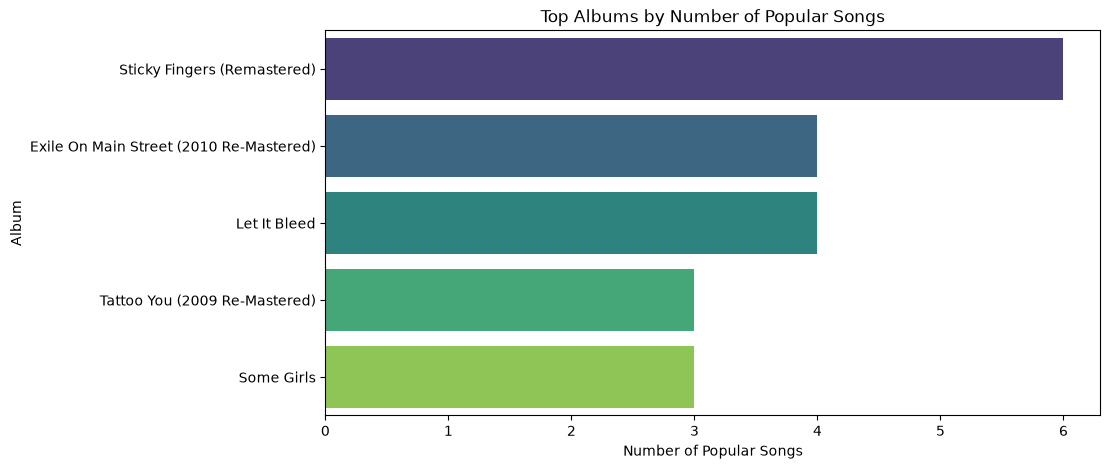

Top two albums based on the number of popular songs:


album
Sticky Fingers (Remastered)                6
Exile On Main Street (2010 Re-Mastered)    4
dtype: int64

In [151]:
# Filter popular songs
popular_songs = df[df["popularity"] >= 50]

# Count popular songs in each album
album_popularity = (
    popular_songs.groupby("album")
    .size()
    .sort_values(ascending=False)
)

# Examine the top five albums
top_albums = album_popularity.head(5)

# Visualize the results
plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_albums.values,
    y=top_albums.index,
    hue=top_albums.index,
    palette="viridis",
    legend=False
)

plt.title("Top Albums by Number of Popular Songs")
plt.xlabel("Number of Popular Songs")
plt.ylabel("Album")
plt.show()

print("Top two albums based on the number of popular songs:")
display(top_albums.head(2))

Based on the selected popularity threshold of 50, the two albums to recommend based on the number of popular songs would be:

- Sticky Fingers (Remastered)
- Exile On Main Street (2010 Re-Mastered)

#### b. Conduct exploratory data analysis to delve into various features of songs, aiming to identify patterns.

The simplest way to examine patterns between features is with a heatmap:

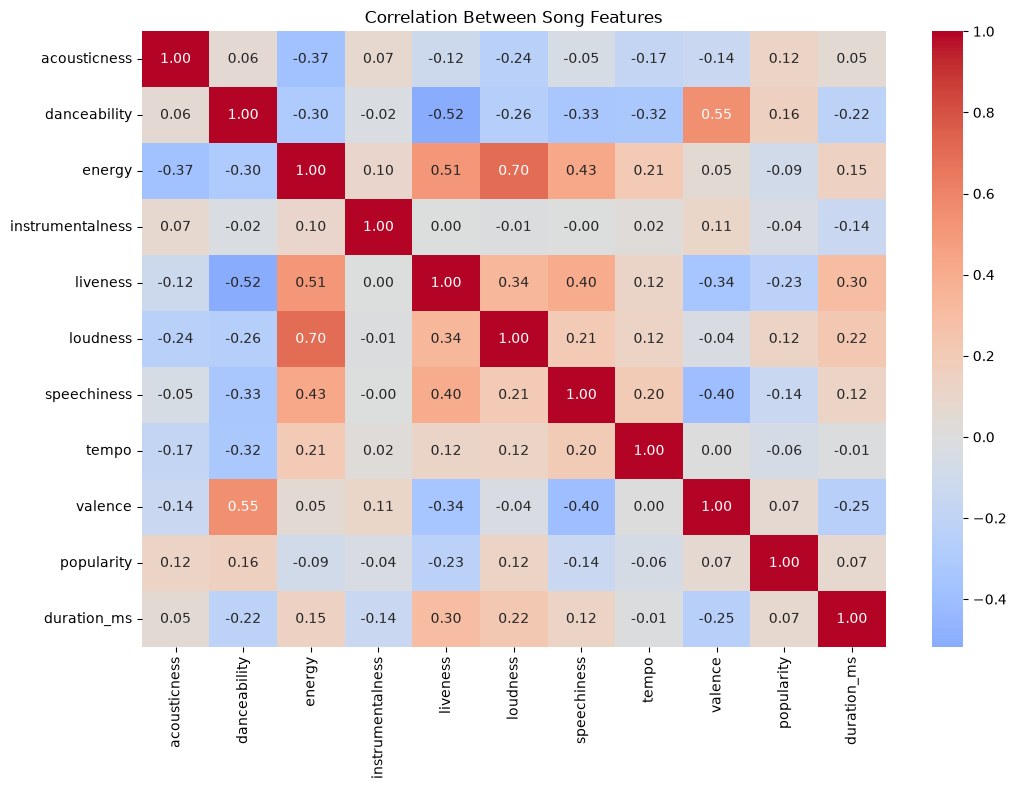

In [152]:
# Examine correlations between numerical features
plt.figure(figsize=(12, 8))

# music_with_popularity contains auditory features and popularity
corr_matrix = df[music_with_popularity].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Song Features")
plt.show()

#### c. Examine the relationship between a song's popularity and various factors, exploring how this correlation has evolved.

We will first check how `popularity` correlates with other features:

In [153]:
# Examine the correlation of "popularity" with other features
popular_corr = corr_matrix["popularity"].drop("popularity")
popular_corr.sort_values(ascending=False).round(2)

danceability        0.16
loudness            0.12
acousticness        0.12
duration_ms         0.07
valence             0.07
instrumentalness   -0.04
tempo              -0.06
energy             -0.09
speechiness        -0.14
liveness           -0.23
Name: popularity, dtype: float64

Interestingly, song popularity is not strongly correlated with any of the other numerical features. There is a weak positive correlation with danceability and a weak negative correlation with liveness (presence of an audience in the recording). This suggests that popularity cannot be explained by general audio characteristics alone.

Let us examine song popularity further by using album release dates:

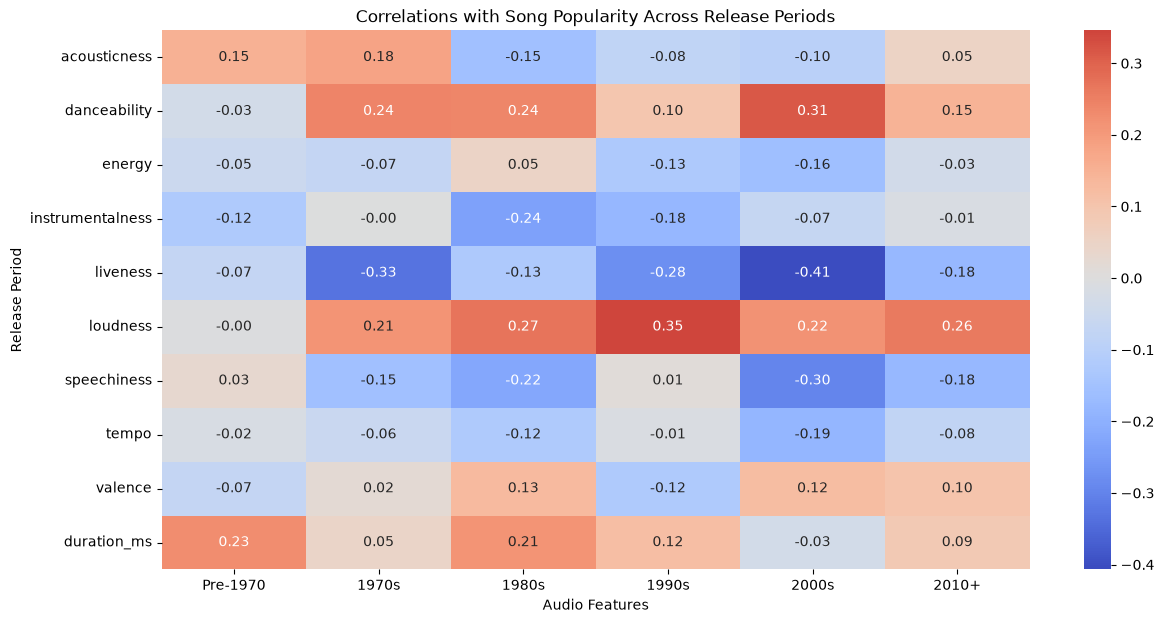

In [154]:
# Extract release year
df["release_year"] = df["release_date"].dt.year

# Create release-period groups
df["release_period"] = pd.cut(
    df["release_year"],
    bins=[1900, 1970, 1980, 1990, 2000, 2010, 2031],
    labels=["Pre-1970", "1970s", "1980s", "1990s", "2000s", "2010+"],
    right=False  # E.g. 1970 would be included in the 1970s category
)

# Store correlations for each release period
correlation_by_period = pd.DataFrame()

for period, group in df.groupby("release_period", observed=True):
    # Get the correlation matrix for this release period
    correlations = group[music_with_popularity].corr()["popularity"]

    # Store "popularity" correlations specifically
    correlation_by_period[period] = correlations.drop("popularity")

plt.figure(figsize=(14, 7))

sns.heatmap(
    correlation_by_period,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlations with Song Popularity Across Release Periods")
plt.xlabel("Audio Features")
plt.ylabel("Release Period")
plt.show()

Overall, loudness and danceability appear increasingly associated with popularity in later release periods, while liveness exhibits the opposite pattern. However, note that these observations represent correlations across different release periods rather than changes in individual songs over time.

Note that these correlations are generally weak to moderate and thus cannot establish causation.

#### d. Provide insights on the significance of dimensionality reduction techniques. Share your ideas and elucidate your observations.

Dimensionality means the number of features in a dataset. Dimensionality reduction decreases that number while trying to preserve important information.

Two benefits of dimensionality reduction are:
- It simplifies computation
- It makes data easier to visualize

We can explore dimensionality reduction via:
- Principal Component Analysis (PCA)
- t-Distributed Stochastic Neighbor Embedding (t-SNE)

First we will explore PCA:

In [155]:
# PCA requires standardized features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[music_cols])

# PCA combines correlated features together into "Principal Components"
pca = PCA()
pca_features = pca.fit_transform(X_scaled)

# Examine the variance captured by the new Principal Components
# The more Principal Components used, the closer the variance is to 1
explained_variance = pd.DataFrame({
    "Explained Variance": pca.explained_variance_ratio_,
    "Cumulative Variance": pca.explained_variance_ratio_.cumsum()
})

display(explained_variance.round(3))

,Explained Variance,Cumulative Variance
0,0.306,0.306
1,0.165,0.471
2,0.114,0.586
3,0.103,0.689
4,0.081,0.771
5,0.071,0.842
6,0.061,0.902
7,0.052,0.955
8,0.028,0.983
9,0.017,1.000


Our objective with PCA is to determine how many principal components are needed to retain a sufficient amount of the original dataset's variance.

For example, we might decide that retaining 90% of the variance is sufficient. In that case, we could use 7 of the 10 available components (based off the current dataset). This can be used for analysis and clustering, but visualizing more than three principal components is difficult using conventional scatterplots. Reducing the data to two or three components allows us to visualize it.

Let us examine using PCA to visualize two components:

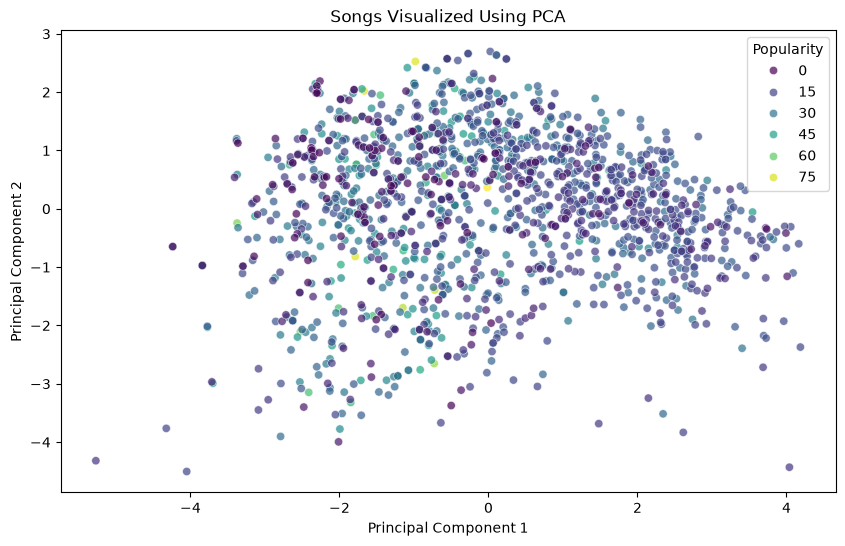

Variance retained: 47.14 %


In [156]:
pca_2d = PCA(n_components=2)
two_features = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))

# All rows for column 0 and column 1
sns.scatterplot(
    x=two_features[:, 0],
    y=two_features[:, 1],
    hue=df["popularity"],
    palette="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Songs Visualized Using PCA")
plt.legend(title="Popularity")
plt.show()

print(
    "Variance retained:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

It is possible to use PCA to reduce the dimensionality of the song dataset from 10 features to two principal components, allowing songs to be visualized in a two-dimensional space. However, these components retain only 47.14% of the total variance, indicating substantial information loss. The visualization does not reveal clearly separated groups, and songs with different popularity scores substantially overlap. Therefore, two components may be useful for visualization but are insufficient to represent most of the variation in the original dataset.

Now we will explore t-SNE:

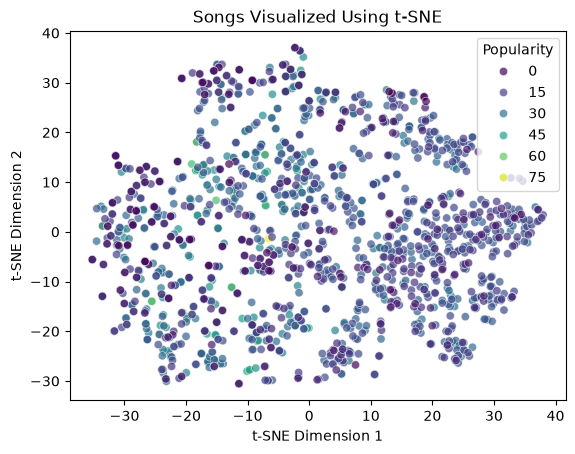

In [157]:
model = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    max_iter=500,
    init="pca",
    learning_rate="auto"
)
map_2d = model.fit_transform(X_scaled)

# All rows for column 1 and column 2
sns.scatterplot(
    x=map_2d[:, 0],
    y=map_2d[:, 1],
    hue=df["popularity"],
    palette="viridis",
    alpha=0.7
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("Songs Visualized Using t-SNE")
plt.legend(title="Popularity")
plt.show()

t-SNE provides a nonlinear, two-dimensional representation of the song dataset, helping visualize local similarities between songs. Although some groupings appear, there is no obvious separation based on popularity. These observations can help guide subsequent clustering analysis.

Unlike PCA, t-SNE focuses on preserving local neighborhood relationships. The distances between widely separated groups should not be interpreted as direct measures of global similarity.

### 4. Perform cluster analysis

#### a. Identify the right number of clusters

The objective is to determine the optimal number of clusters $k$ for grouping songs based on their audio characteristics.

We will combine two methods:

1. Elbow Method: Identifies the point at which increasing the number of clusters produces diminishing reductions in *within-cluster sum of squares* (WCSS).

2. Silhouette Score: Measures how well each song fits within its assigned cluster compared with neighboring clusters. Higher scores indicate better-defined clusters.

We will focus purely on musical characteristics and so will drop `popularity`.

In [158]:
# Standardize features
# music_cols is all musical features and excludes popularity
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[music_cols])

wcss = []
silhouette_scores = []

k_range = range(2, len(music_cols))

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    # Store the WCSS score
    wcss.append(kmeans.inertia_)

    # Store the silhouette score
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

pd.DataFrame({
    "Cluster": k_range,
    "Silhouette Scores": silhouette_scores,
    "WCSS": wcss
})

,Cluster,Silhouette Scores,WCSS
0,2,0.202622,11664.832581
1,3,0.182698,10231.979311
2,4,0.172722,9480.485982
3,5,0.146572,8813.168560
4,6,0.141608,8264.694792
5,7,0.153086,7793.733743
6,8,0.149040,7377.167182
7,9,0.161949,7040.739138


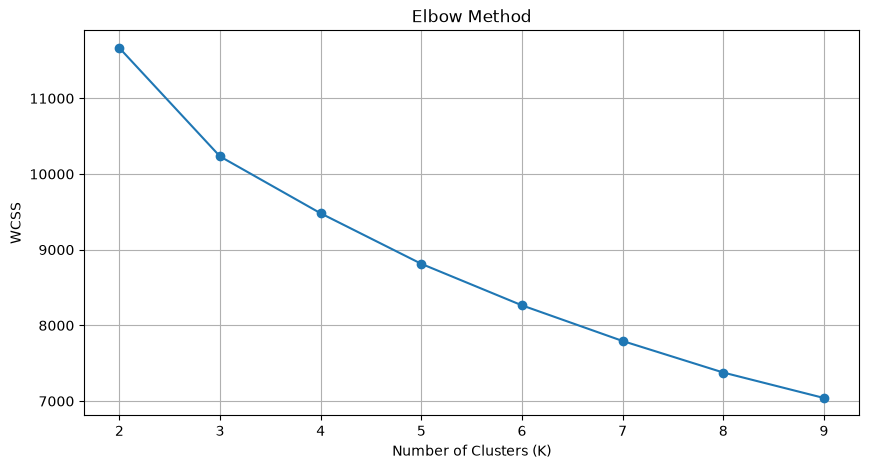

In [159]:
plt.figure(figsize=(10, 5))

plt.plot(
    k_range,
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.xticks(list(k_range))
plt.grid()
plt.show()

**Elbow Method**

The WCSS decreases as $k$ increases, as expected. However, the curve is ambiguous and there is no particularly sharp elbow. Let us see if the Silhouette Score provides a clearer answer.

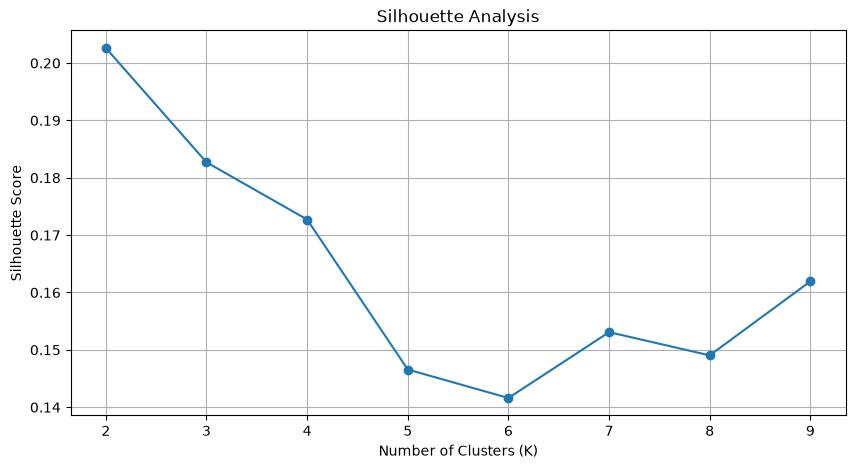

In [160]:
plt.figure(figsize=(10, 5))

plt.plot(
    k_range,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")

plt.xticks(list(k_range))
plt.grid()
plt.show()

**Silhouette Analysis**

The highest score occurs at $k = 2$. This suggests that two clusters provide the best separation among the tested configurations. However, all scores are relatively low, suggesting substantial overlap between clusters.

**Strategy for Clusters**

The silhouette analysis favors $k = 2$ clusters, while the elbow method does not indicate a particularly clear optimum. 

Although two clusters achieved a higher silhouette score, we will proceed with $k = 3$ clusters because our primary objective is to create useful song cohorts rather than simply maximize cluster separation. Three clusters provide greater musical differentiation, allowing us to identify more distinct song characteristics and potentially make more relevant recommendations.

#### b. Use appropriate clustering algorithms

We will examine two clustering algorithms to group songs using our selected value of $k=3$:

- K-Means: Partitions songs into $k$ clusters based on similarity
  - Iteratively measures the distance between data points and centroids, then recalculates centroids based on the means of their assigned points
- Agglomerative Clustering: Uses a hierarchical approach to group songs
  - Repeatedly merges nearby data points or clusters until the desired number of clusters is reached

A third option is DBSCAN, which identifies clusters based on density and selected hyperparameters. However, given that we want to examine a specific count of clusters $k$, we will not use DBSCAN here.

In [161]:
X = df[music_cols]
k_value = 3

# Initialize K-Means
kmeans = KMeans(
    n_clusters=k_value,
    random_state=42,
    n_init=10
)

# Fit the model and assign clusters
kmeans_labels = kmeans.fit_predict(X_scaled)

# Store cluster assignments
df["KMeans_Cluster"] = kmeans_labels

# Examine cluster distribution
print(df["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0    604
1    547
2    336
Name: count, dtype: int64


In [162]:
# Initialize Agglomerative Clustering
agg = AgglomerativeClustering(
    n_clusters=k_value,
    linkage="ward"  # Minimize variance of merged clusters
)

# Fit the model and assign clusters
agg_labels = agg.fit_predict(X_scaled)

# Store cluster assignments
df["Agglomerative_Cluster"] = agg_labels

# Examine cluster distribution
print(df["Agglomerative_Cluster"].value_counts().sort_index())

Agglomerative_Cluster
0    585
1    564
2    338
Name: count, dtype: int64


In [163]:
kmeans_score = silhouette_score(X_scaled, kmeans_labels)
agg_score = silhouette_score(X_scaled, agg_labels)

print("K-Means Silhouette Score:", round(kmeans_score, 4))
print("Agglomerative Silhouette Score:", round(agg_score, 4))

K-Means Silhouette Score: 0.1827
Agglomerative Silhouette Score: 0.1505


Since K-Means achieves a higher silhouette score, we will use it for the remaining cluster analysis. That being said, the score itself is close to 0 rather than to 1, which suggests that many points are near cluster boundaries.

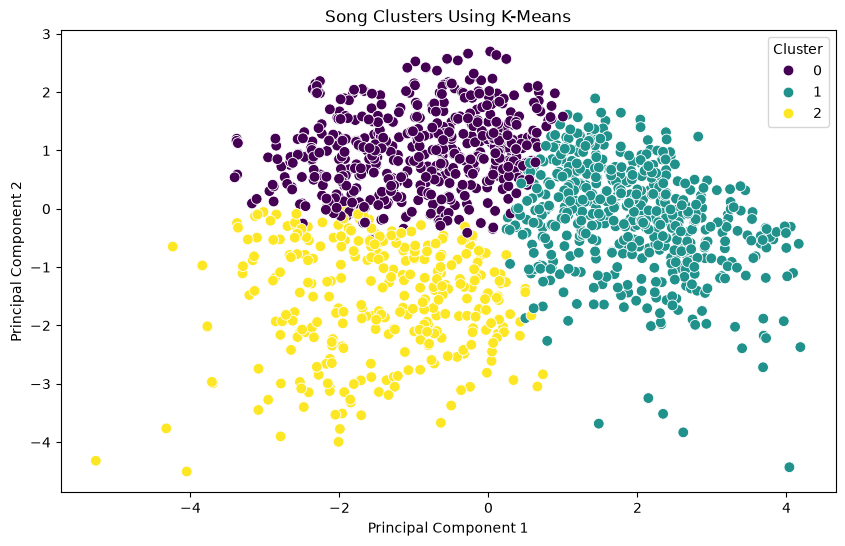

In [164]:
plt.figure(figsize=(10, 6))

# Use the two-dimensional PCA representation created earlier
sns.scatterplot(
    x=two_features[:, 0],
    y=two_features[:, 1],
    hue=kmeans_labels,
    palette="viridis",
    s=60
)

plt.title("Song Clusters Using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

#### c. Define each cluster based on the features

First we will examine the feature values for each cluster, and also a heatmap.

In [165]:
# Calculate average audio features for each cluster
cluster_means = df.groupby("KMeans_Cluster")[music_cols].mean()

display(cluster_means.round(2))

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,duration_ms
KMeans_Cluster,,,,,,,,,,
0,0.19,0.55,0.81,0.23,0.30,-6.91,0.05,124.21,0.78,220242.68
1,0.19,0.36,0.93,0.16,0.83,-5.24,0.11,137.89,0.45,304047.66
2,0.45,0.49,0.56,0.09,0.30,-9.46,0.05,110.26,0.44,252852.79


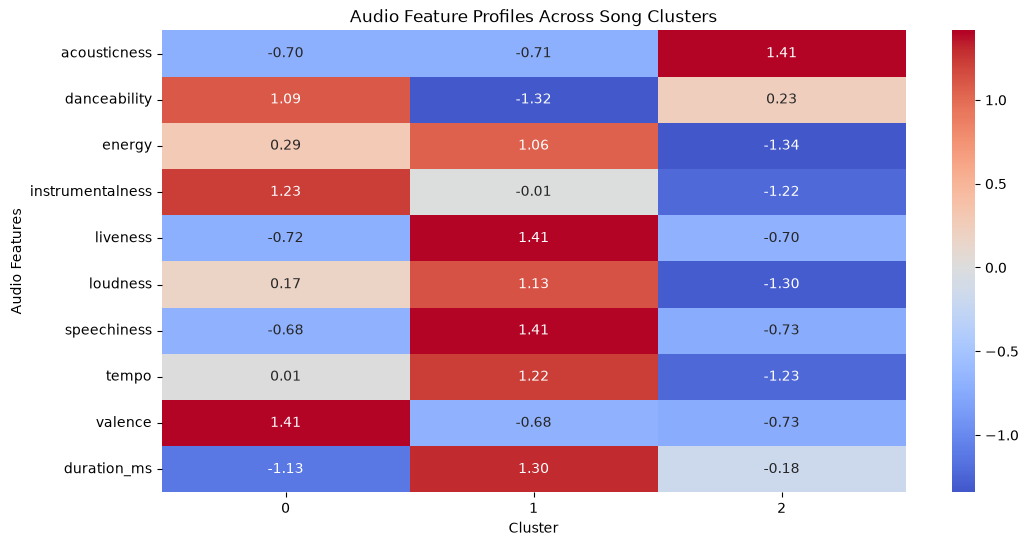

In [166]:
# Standardize cluster averages by feature
# We use Z-score scaling to put features on a common scale
cluster_means_scaled = cluster_means.apply(zscore, axis=0)

plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_means_scaled.transpose(),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Audio Feature Profiles Across Song Clusters")
plt.ylabel("Audio Features")
plt.xlabel("Cluster")
plt.show()

The clustering algorithm has identified three groups with different musical characteristics.

**Cluster 0** contains the highest danceability, instrumentalness, and valence. These songs tend to be danceable and positive-sounding, with few vocals.

**Cluster 1** contains the highest energy, liveness, loudness, speechiness, tempo, and duration. These songs tend to be energetic, loud, and fast-paced. Their high liveness score suggests a greater likelihood of live audience presence in the recordings.

**Cluster 2** contains the highest acousticness, but the lowest energy, instrumentalness, loudness, and tempo. These songs tend to be more acoustic, softer, and mellower.

The PCA visualization provides some visual evidence of these groupings, although the clusters overlap in certain regions. Since the two components retain only 47.14% of the original variance, the visualization represents only part of the underlying data structure.

These cohorts can be useful for music recommendations. For example, listeners who enjoy energetic live performances can be recommended songs from Cluster 1, while listeners who prefer acoustic and mellow songs can be recommended songs from Cluster 2.